# Graph-based optimization of a DSG

Below is shown how a design space can be built using the DSG and optimized with SBArchOpt's graph surrogate. The alternatives are one processor or two processors of a common size `s in [0, 1]`, with a sizing variable on each branch.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from pymoo.optimize import minimize

from adsg_core import BasicDSG, NamedNode, DesignVariableNode, MetricNode, MetricType, DSGEvaluator
from adsg_core.optimization.graph_decoder import DSGGraphDecoder
from sb_arch_opt.algo.arch_sbo import get_sbo
from sb_arch_opt.algo.arch_sbo.graph import CompositeGraphKernel, LdWloa, SizingKernel
from sb_arch_opt.algo.arch_sbo.infill import get_default_infill
from sb_arch_opt.algo.arch_sbo.models import ModelFactory

SEED = 42
N_INIT = 10
BATCH_SIZE = 2
MAX_EVALS = 24

## Building the Design Space

A selection choice in `BasicDSG` activates either the single-processor or two-processor branch. Each branch has its own sizing variable, so exactly one size is active in a completed design. The objective node is attached to the system root and remains present for both alternatives.

In [2]:
system = NamedNode("System")
single = NamedNode("Single processor")
double = NamedNode("Two processors")
single_size = DesignVariableNode("single_size", bounds=(0.0, 1.0))
double_size = DesignVariableNode("double_size", bounds=(0.0, 1.0))
loss = MetricNode("loss", direction=-1, type_=MetricType.OBJECTIVE)

dsg = BasicDSG()
dsg.add_selection_choice("architecture", system, [single, double])
dsg.add_edges([
    (system, loss),
    (single, single_size),
    (double, double_size),
    (double, NamedNode("Processor 1")),
    (double, NamedNode("Processor 2")),
])
dsg = dsg.set_start_nodes({system})
dsg.render()

## Defining the Evaluation Function

The evaluation function is implemented by extending `DSGEvaluator` and overriding `_evaluate`. It receives a completed graph and the requested metric nodes. The remaining sizing node identifies the selected branch and supplies its size; the returned dictionary maps each metric node to its calculated value.

In [3]:
class ProcessorEvaluator(DSGEvaluator):
    def _evaluate(self, graph, metric_nodes):
        size_node = graph.des_var_nodes[0]
        n_processors = 1 if size_node.name == "single_size" else 2
        size = graph.des_var_value(size_node)
        value = (n_processors * size - 1.4)**2 + 0.1 * n_processors
        return {metric_nodes[0]: value}

evaluator = ProcessorEvaluator(dsg)
problem = evaluator.get_problem(parallel_processes=False)

## Constructing the Graph Surrogate

`DSGGraphDecoder` uses the evaluator's graph processor to resolve design vectors and export graphs, constant and DSG-role labels, and normalized sizing values. Inactive numeric variables are imputed to their midpoint. `LdWloa` compares the exported graphs and labels, and `SizingKernel` compares the sizing values. Their composite includes both similarities and their product; `ModelFactory` creates the surrogate and input normalization.

In [4]:
# Decoder that can deconstruct a design vector into it's associated DSG graph instance
decoder = DSGGraphDecoder(evaluator)

# Define the composite kernel consisting of a graph kernel for
# structural similarity and a sizing kernel for sizing parameters
kernel = CompositeGraphKernel(
    branches=[
        LdWloa(cutoff=2, labelings=decoder.selected_labelings),
        SizingKernel(decoder.sizing_features),
    ],
    composition="additive_interaction",
)

# Define the graph kernel surrogate model
surrogate, normalization = ModelFactory(problem).get_graph_kriging_model(
    decoder=decoder,
    kernel=kernel,
    multi=False,
    seed=SEED,
    n_start=1,
)

## Running the Optimization

The run starts with ten evaluations and adds two designs per infill batch until 24 designs have been evaluated. The problem wrapper uses the evaluator to resolve and evaluate each design; the same evaluator supplies the graph processor used by the decoder.

In [5]:
# Get the infill criterion
infill, _ = get_default_infill(problem, n_parallel=BATCH_SIZE)

# Prepare an infill point optimisation SBO algorithm that uses the graph-kernel / sizing kernel hybrid surrogate.
algorithm = get_sbo(
    surrogate_model=surrogate,
    infill=infill,
    init_size=N_INIT,
    infill_size=BATCH_SIZE,
    infill_pop_size=30,
    infill_gens=10,
    normalization=normalization,
)

# Optimize designs
result = minimize(
    problem, algorithm,
    termination=("n_evals", MAX_EVALS),
    seed=SEED,
    verbose=False,
)

## Recovering the Selected Design

`get_graph` converts the best design vector back into a DSG instance. The remaining sizing node identifies the selected branch and its size. The plot shows the best objective observed as evaluations accumulate; the dashed line marks the known minimum of 0.2.

Selected size variable: double_size
Size: 0.700
Best objective: 0.2000; known optimum: 0.2000


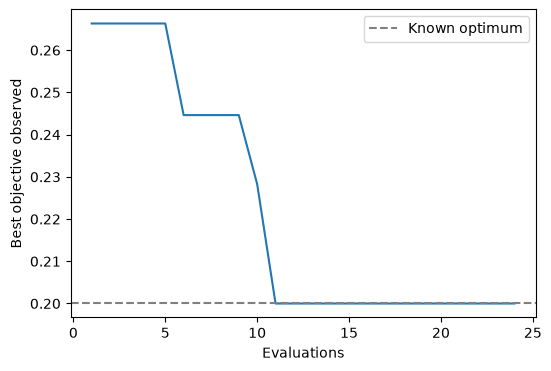

In [6]:
best_graph, _, _ = evaluator.get_graph(result.X)
best_size = best_graph.des_var_nodes[0]
print(f"Selected size variable: {best_size.name}")
print(f"Size: {best_graph.des_var_value(best_size):.3f}")
print(f"Best objective: {result.F[0]:.4f}; known optimum: 0.2000")

values = result.pop.get("F")[:, 0]
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.arange(1, len(values) + 1), np.minimum.accumulate(values))
ax.axhline(0.2, color="grey", linestyle="--", label="Known optimum")
ax.set(xlabel="Evaluations", ylabel="Best objective observed")
ax.legend()
plt.show()